# 04 · Slice models

Trains image models on single slices and their neighbours, and chooses what they see and which network they use: the input channels and the window, the crop to the head, the resolution and the backbone. The two best backbones are then trained on all five folds and scored on the test set. Each section ends with key findings.

**Contents**
1. Setting up the training (section 1)
2. Measuring the seed noise of a slice model (section 2)
3. Choosing the input channels (section 3)
4. Tuning the window (section 4)
5. Cropping to the head (section 5)
6. Choosing the resolution (section 6)
7. Choosing the backbone (section 7)
8. Training the two best backbones on five folds (section 8)
9. Predicting the test set (section 9)

No model is trained here. The runs were made with `scripts/train_slice.py` (the command of each run is printed in its section); this notebook reads their saved predictions and scores them again. Needs:
- the slice table `slices.csv` and the PNG 16-bit store `png16/` from 02;
- the runs in `outputs/runs/` (one folder per run: its setup, a log per epoch and the validation predictions of every epoch);
- for section 9, the test predictions of the final models from `scripts/extract_features.py` and `scripts/predict_test_flip.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
from sklearn.metrics import roc_auc_score

from ich.data.crop import MIN_SIDE, crop, series_boxes, slice_boxes
from ich.data.prepare import LABELS, STORE, read_table, store_path
from ich.data.windows import MODEL_WINDOWS
from ich.metrics import image_losses, paired_bootstrap, score
from ich.paths import load_paths
from ich.submission import check_submission, to_submission

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR, PROCESSED, OUTPUTS = paths["raw_data_dir"], paths["processed_data_dir"], paths["outputs_dir"]
RUNS, FEATURES = OUTPUTS / "runs", OUTPUTS / "features"

table = read_table(PROCESSED / "slices.csv")
train = table[table["split"] == "train"].reset_index(drop=True)
position_labels = train.set_index("image")[LABELS].astype(float)  # a kept slice: the labels of its position (02, 3.1)


def config(run):
    return json.loads((RUNS / run / "config.json").read_text())


def log(run):
    return pd.read_csv(RUNS / run / "log.csv")


def probs(run, epoch):
    return np.load(RUNS / run / f"val_epoch{epoch}.npy")


def best_epoch(run):
    return int(log(run)["kept"].idxmin()) + 1


DEFAULTS = {"fold": 0, "backbone": "seresnext50_32x4d", "slices": 1, "windows": ["brain", "subdural", "bone"], "crop": "series",
            "size": 256, "epochs": 3, "train_share": 0.75, "batch": 192, "accumulate": 1, "lr": 3.5e-4, "dropout": 0.2,
            "jitter": False, "seed": 0, "embeddings": False, "val_full": False}


def command(run):
    # The command of a run, rebuilt from its config.json: only the arguments that differ from the defaults.
    c, parts = config(run), [f"python scripts/train_slice.py --name {run}"]
    for key, default in DEFAULTS.items():
        value = c.get(key, default)
        value = default if value is None else value
        if value == default:
            continue
        flag = "--" + key.replace("_", "-")
        parts.append(flag if value is True else f"{flag} {' '.join(value) if isinstance(value, list) else value}")
    return " ".join(parts)


# fold 0: the same validation slices, in the same order, in every fold-0 run
val = pd.read_csv(RUNS / "a1_3x1" / "val.csv")
fold0_runs = [r.name for r in sorted(RUNS.iterdir()) if (r / "val_epoch3.npy").exists() and config(r.name)["fold"] == 0]
assert all(pd.read_csv(RUNS / r / "val.csv")["image"].equals(val["image"]) for r in fold0_runs)
kept = val["keep"].to_numpy()
y = position_labels.loc[val["image"][kept]].to_numpy()
groups = val["patient"][kept].to_numpy()
print(f"{len(fold0_runs)} fold-0 runs | validation: {len(val):,} slices ({kept.sum():,} kept), {val['patient'].nunique():,} patients")

23 fold-0 runs | validation: 150,537 slices (149,017 kept), 3,787 patients


In [2]:
def difference(p_from, p_to):
    # Score of p_to minus that of p_from on the kept fold-0 slices, with the 95% interval of a patient bootstrap (03, 6).
    return paired_bootstrap(image_losses(y, p_from), image_losses(y, p_to), groups)


def interval(d):
    return f"{d['mean']:+.4f} [{d['low']:+.4f}, {d['high']:+.4f}]"


def compare(runs, extra=None):
    # The score (kept slices) and the mean AUROC of the six labels of each run at its best epoch, then the difference of
    # every other run to the best one, with the 95% interval of a patient bootstrap. Returns the predictions.
    p = {name: probs(run, best_epoch(run))[kept] for name, run in runs.items()}
    result = pd.DataFrame({"score": {name: score(y, v) for name, v in p.items()},
                           "AUROC": {name: log(run).loc[best_epoch(run) - 1, "auc mean"] for name, run in runs.items()}})
    for column, values in (extra or {}).items():
        result[column] = pd.Series(values)
    display(result.round(4))
    best = result["score"].idxmin()
    print(f"difference to the best ({best}):")
    for name in runs:
        if name != best:
            print(f"  {name} − {best}: {interval(difference(p[best], p[name]))}")
    return p

## 1. Setting up the training

Every run trains one model on one fold and predicts the slices of its validation fold after every epoch. The setup shared by all runs:

| Part | Setup |
|---|---|
| model | a pretrained timm backbone, global average pooling, dropout 0.2 and one linear layer to the six labels; the bias of that layer starts at the logit of each label's rate |
| input | the stored values (HU + 1024) turned into windows on the GPU, scaled to [0, 1] and normalised; the first layer of the backbone takes as many channels as the input has |
| loss | the competition loss: binary cross-entropy per label, `any` counted twice, divided by 7 |
| optimiser | AdamW, learning rate 3.5e-4, weight decay 0.01; 5% of the steps of linear warm-up, then a cosine decay to 0; bfloat16 mixed precision |
| batch | 192 slices; a larger input is split into 2–6 parts whose gradients are summed (gradient accumulation), so every run takes the same steps |
| augmentation | random horizontal flip, rotation up to ±15°, zoom up to ±10% and shift up to ±5% of the side, one draw per slice |
| epochs | 3 |

**Training slices.** The kept slices of the other four folds with the labels of their position, as in 03. The runs of sections 3–5 and 7.1 and the second pair of section 2 use 75% of these patients to save time, the same patients in every run (drawn once, within each writer and bleed / no bleed group); the first pair of section 2 uses 50%; sections 6, 7.2 and 8 use all of them.

**Validation.** All slices of the validation fold are predicted; the score uses the kept slices with the labels of their position (03, 2). At 256 px, a run whose crop matches a cropped store reads its validation slices from that store, whose files equal the crops made on the fly from the full images (checked once for every slice of fold 0). At 512 px every validation slice is read from the full image and cropped on the fly, as the test images are.

**Decisions** use the score of each run at the best of its three epochs. Tables show the score on the kept slices and the mean AUROC of the six labels; below each table, every run is compared with the best one on the same fold-0 slices with the paired patient bootstrap of 03, 6. A difference counts if it is larger than the seed noise of section 2.

The number of training and validation slices, with 75% and with all patients:

In [3]:
for run in ["a1_3x1", "b1_res256"]:
    first = (OUTPUTS / "logs" / f"{run}.log").read_text().splitlines()
    print(f"{run} ({config(run)['train_share']:.0%} of the patients): {next(line for line in first if line.startswith('train:'))}")

a1_3x1 (75% of the patients): train: 448,030 slices, 11,363 patients | val: 150,537 slices (149,017 kept), 3,787 patients
b1_res256 (100% of the patients): train: 596,892 slices, 15,151 patients | val: 150,537 slices (149,017 kept), 3,787 patients


What a model sees in training: the first training batch of the final setup (section 8) after augmentation, 3 of 8 slices. Each row is one sample, its three channels side by side: the kept slices one position below, at and one position above the slice, in the subdural window.

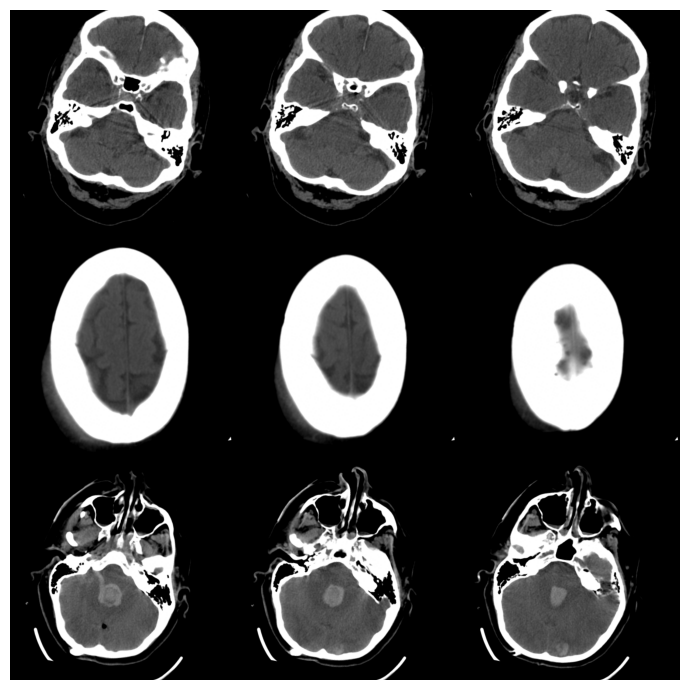

In [4]:
inputs = plt.imread(RUNS / "b3_512_convnext_tiny" / "inputs.png")
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(inputs[: 3 * 512], cmap="gray", vmin=0, vmax=1)
ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Measuring the seed noise of a slice model

The seed sets the initial weights of the last layer, the order of the batches and the augmentation. Two pairs of runs differ only in it: the first setup tried (one slice in the brain, subdural and bone windows, 50% of the patients, batch 64, learning rate 2e-4) and the 3×1 input of section 3. Their scores, the difference within each pair and what the mean of the two seeds gives:

In [5]:
for a, b in [("s01_base_seed0", "s01_base_seed1"), ("a1_3x1", "a1_3x1_seed1")]:
    print(command(a), "\n", command(b))
pairs = {"first setup": ("s01_base_seed0", "s01_base_seed1"), "3×1 subdural": ("a1_3x1", "a1_3x1_seed1")}
rows = []
for name, (a, b) in pairs.items():
    pa, pb = probs(a, best_epoch(a))[kept], probs(b, best_epoch(b))[kept]
    rows.append({"": name, "seed 0": score(y, pa), "seed 1": score(y, pb), "seed 1 − seed 0": interval(difference(pa, pb)),
                 "mean of the two seeds": score(y, (pa + pb) / 2), "mean − seed 0": interval(difference(pa, (pa + pb) / 2))})
pd.DataFrame(rows).set_index("").round(4)

python scripts/train_slice.py --name s01_base_seed0 --train-share 0.5 --batch 64 --lr 0.0002 
 python scripts/train_slice.py --name s01_base_seed1 --train-share 0.5 --batch 64 --lr 0.0002 --seed 1
python scripts/train_slice.py --name a1_3x1 --slices 3 --windows subdural 
 python scripts/train_slice.py --name a1_3x1_seed1 --slices 3 --windows subdural --seed 1


,seed 0,seed 1,seed 1 − seed 0,mean of the two seeds,mean − seed 0
,,,,,
first setup,0.0758,0.0752,"-0.0007 [-0.0016, +0.0002]",0.0724,"-0.0034 [-0.0039, -0.0029]"
3×1 subdural,0.0748,0.0748,"-0.0001 [-0.0011, +0.0009]",0.0714,"-0.0034 [-0.0040, -0.0028]"


### 2.1 Key findings

- **Two seeds differ by 0.0007 and 0.0001,** with intervals about ±0.001 around their difference, both covering zero.
- So a difference has to be larger than **0.001** to count as a gain; smaller ones are treated as noise in the sections below.
- **The mean of two seeds is 0.0034 better than one seed**, in both pairs: averaging models gains more than most single changes in this notebook.

## 3. Choosing the input channels

A slice can be given in one or three windows, alone or with its neighbours. The windows (level, width in HU, fixed, never from the file header; 01):

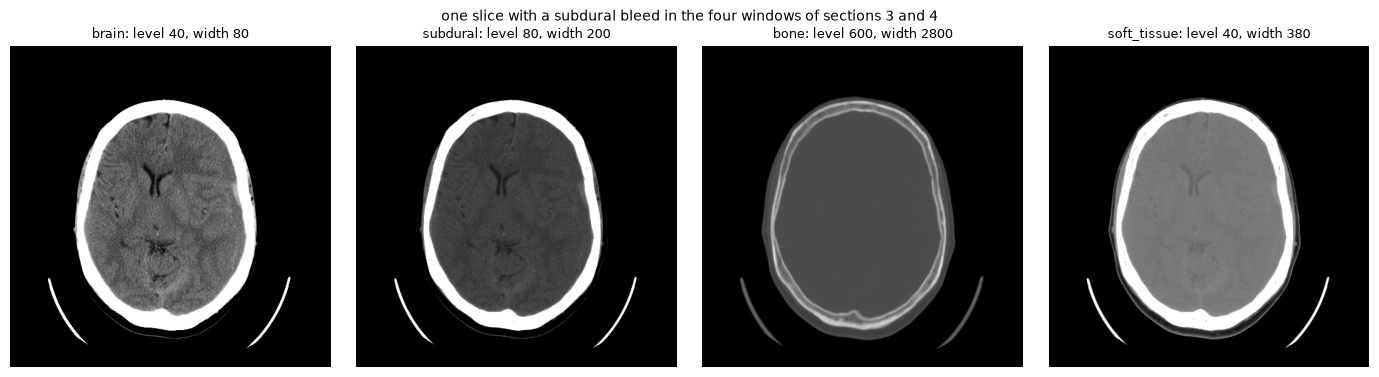

In [6]:
example = train[train["keep"] & (train["subdural"] == 1) & (train["fold"] == 0)].sample(1, random_state=3).iloc[0]
stored = STORE.decode(store_path(PROCESSED / "png16", example["image"]).read_bytes()).astype(np.float32) - 1024
names = ["brain", "subdural", "bone", "soft_tissue"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, name in zip(axes, names):
    level, width = MODEL_WINDOWS[name]
    ax.imshow(np.clip((stored - level + width / 2) / width, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}: level {level}, width {width}", fontsize=9)
    ax.axis("off")
fig.suptitle("one slice with a subdural bleed in the four windows of sections 3 and 4", fontsize=10)
plt.tight_layout()
plt.show()

Four inputs, named slices × windows:
- **1×1:** the slice in the subdural window;
- **1×3:** the slice in the brain, subdural and bone windows;
- **3×1:** the kept slices one position below, at and above, in the subdural window (2.5D); at the ends of a scan the slice itself fills the missing neighbour;
- **3×3:** the three slices in the three windows, 9 channels.

All four use seresnext50, 256 px and the box of the series (section 5), without window jitter (section 4):

In [7]:
runs = {"1×1": "a1_1x1", "1×3": "a1_1x3", "3×1": "a1_3x1", "3×3": "a1_3x3"}
for run in runs.values():
    print(command(run))
p = compare(runs)

python scripts/train_slice.py --name a1_1x1 --windows subdural
python scripts/train_slice.py --name a1_1x3
python scripts/train_slice.py --name a1_3x1 --slices 3 --windows subdural
python scripts/train_slice.py --name a1_3x3 --slices 3


,score,AUROC
1×1,0.0754,0.9747
1×3,0.0765,0.9756
3×1,0.0748,0.9748
3×3,0.0771,0.9742


difference to the best (3×1):


  1×1 − 3×1: +0.0005 [-0.0005, +0.0016]


  1×3 − 3×1: +0.0017 [+0.0004, +0.0029]


  3×3 − 3×1: +0.0022 [+0.0012, +0.0032]


What the mean of the 1×1 and the 3×1 model gives:

In [8]:
print(f"mean of 1×1 and 3×1: {score(y, (p['1×1'] + p['3×1']) / 2):.4f} | − 3×1:", interval(difference(p["3×1"], (p["1×1"] + p["3×1"]) / 2)))

mean of 1×1 and 3×1: 0.0701 | − 3×1: -0.0047 [-0.0053, -0.0042]


### 3.1 Key findings

- **3×1 scores best (0.0748), but 1×1 is only 0.0005 worse,** within the noise: the neighbours alone add little at 256 px.
- **More windows make it worse:** 1×3 is 0.0017 and 3×3 0.0022 worse than 3×1. In this setup the extra windows do not help.
- **1×1 and 3×1 complement each other:** their mean scores 0.0701, 0.0047 better than 3×1 alone. 3×1 is the input of the following sections; 1×1 is kept for the sequence models of 05.

## 4. Tuning the window

Two changes to the 3×1 subdural input:
- **window jitter:** in training, every slice gets its own random shift of the window level (±10 HU) and scale of its width (±10%); validation uses the fixed window;
- **soft tissue window** (level 40, width 380, about twice as wide as subdural, the third window of the 2nd place) instead of subdural.

In [9]:
runs = {"subdural": "a1_3x1", "subdural + jitter": "a2_3x1_jitter", "soft tissue": "a2_3x1_soft"}
for run in runs.values():
    print(command(run))
p = compare(runs)

python scripts/train_slice.py --name a1_3x1 --slices 3 --windows subdural
python scripts/train_slice.py --name a2_3x1_jitter --slices 3 --windows subdural --jitter
python scripts/train_slice.py --name a2_3x1_soft --slices 3 --windows soft_tissue


,score,AUROC
subdural,0.0748,0.9748
subdural + jitter,0.0740,0.9743
soft tissue,0.0758,0.9738


difference to the best (subdural + jitter):


  subdural − subdural + jitter: +0.0008 [-0.0003, +0.0018]


  soft tissue − subdural + jitter: +0.0017 [+0.0009, +0.0026]


The soft tissue run has no jitter, so the window alone is compared with the fixed subdural window:

In [10]:
print("soft tissue − subdural, both without jitter:", interval(difference(p["subdural"], p["soft tissue"])))

soft tissue − subdural, both without jitter: +0.0010 [-0.0001, +0.0021]


### 4.1 Key findings

- **Window jitter scores best (0.0740),** 0.0008 better than the fixed window, below the noise threshold. It costs nothing and was kept in every later run.
- **The soft tissue window is not better:** against the fixed subdural window, both without jitter, it scores +0.0010 [−0.0001, +0.0021]; the subdural window stays.

## 5. Cropping to the head

The head fills only part of the 512 × 512 image (02, 7.3). Cutting a square box around it and resizing the box to the input size gives the head more pixels. Three boxes, from the head box of every slice (02, 7.3) plus a margin of 8 pixels (`src/ich/data/crop.py`):
- **series box:** one box around the head boxes of all slices of the series, the same for every slice;
- **slice box:** the box of the slice itself; with neighbours as channels, the box of the centre slice cuts all three;
- **slice box ≥ 256 px:** the same, grown to a side of at least 256 pixels around the same centre, so a small box at the top of the head is enlarged less.

A box can reach past the image; the part outside is air. The sides of the three boxes on the kept train slices (pixels of the 512 image):

In [11]:
boxes = {"series box": train[["series"]].join(series_boxes(train), on="series")[["top", "left", "side"]],
         "slice box": slice_boxes(train), "slice box ≥ 256 px": slice_boxes(train, min_side=MIN_SIDE)}
k = train["keep"].to_numpy()
sides = pd.DataFrame({name: b["side"][k].describe(percentiles=[0.1, 0.5, 0.9]) for name, b in boxes.items()}).T
sides = sides[["10%", "50%", "90%"]].astype(int)
sides["slices with a side below 256"] = [f"{(b['side'][k] < 256).mean():.1%}" for b in boxes.values()]
sides

,10%,50%,90%,slices with a side below 256
series box,428,474,518,0.0%
slice box,254,401,455,10.2%
slice box ≥ 256 px,256,401,455,0.0%


What the model sees with each crop, for slices from the top to the bottom of one scan with a bleed. Left: the full image with the series box (green) and the slice box ≥ 256 px (red):

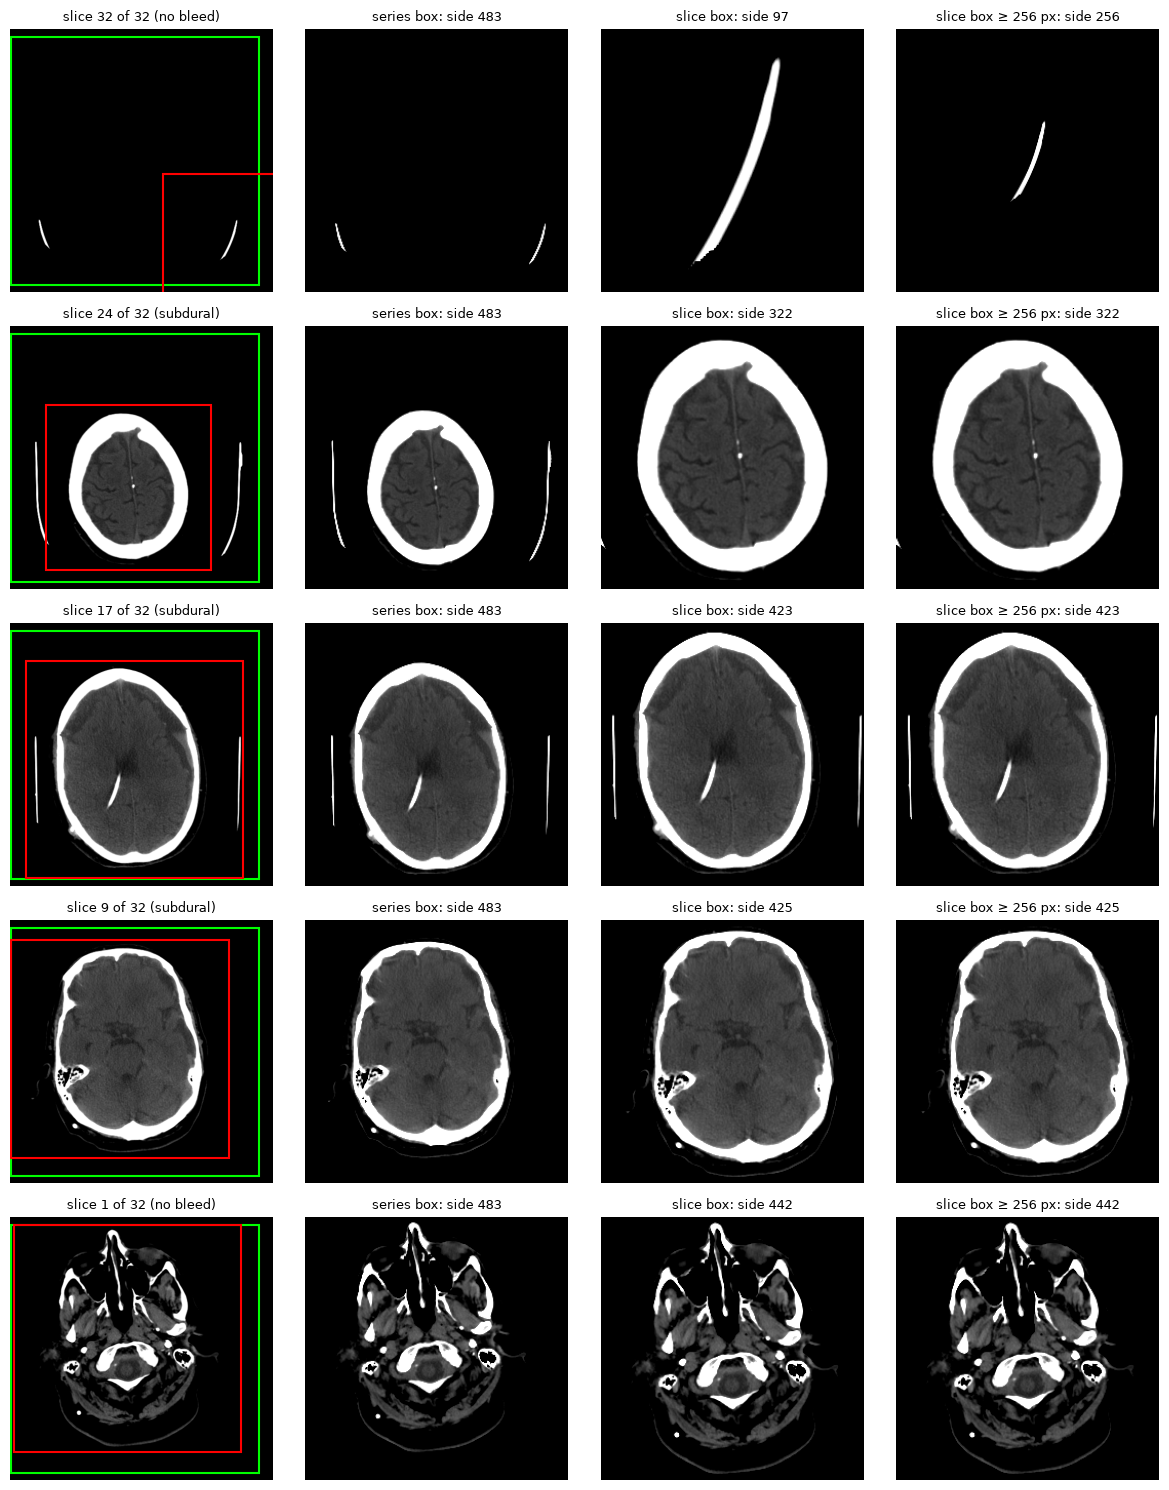

In [12]:
level, width = MODEL_WINDOWS["subdural"]


def shown(values):
    return np.clip((values.astype(np.float32) - 1024 - level + width / 2) / width, 0, 1)


scan_ids = train[train["keep"] & (train["fold"] == 0) & (train["n_slices"] >= 30) & (train["any"] == 1)]["series"].unique()
scan = train[train["keep"] & (train["series"] == np.random.default_rng(1).choice(scan_ids))].sort_values("slice")
rows = scan.index[np.linspace(0, len(scan) - 1, 5).round().astype(int)][::-1]
fig, axes = plt.subplots(len(rows), 4, figsize=(12, 3 * len(rows)))
for r, i in enumerate(rows):
    stored = STORE.decode(store_path(PROCESSED / "png16", train.loc[i, "image"]).read_bytes())
    axes[r, 0].imshow(shown(stored), cmap="gray")
    for name, colour in [("series box", "lime"), ("slice box ≥ 256 px", "red")]:
        top, left, side = boxes[name].loc[i]
        axes[r, 0].add_patch(plt.Rectangle((left, top), side, side, fill=False, color=colour, linewidth=1.5))
    bleeds = ", ".join(label for label in LABELS[:-1] if train.loc[i, label]) or "no bleed"
    axes[r, 0].set_title(f"slice {train.loc[i, 'slice'] + 1} of {train.loc[i, 'n_slices']} ({bleeds})", fontsize=9)
    for c, name in enumerate(["series box", "slice box", "slice box ≥ 256 px"], start=1):
        axes[r, c].imshow(shown(crop(stored, *boxes[name].loc[i])), cmap="gray")
        axes[r, c].set_title(f"{name}: side {boxes[name].loc[i, 'side']}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

At the top of the head the slice box can be tiny or lock onto the arcs of the head holder (first row); the box of at least 256 px limits how far such a box is enlarged.

The four crops, with the 3×1 subdural input and window jitter (seresnext50, 256 px):

In [13]:
runs = {"no crop": "a3_3x1_nocrop", "series box": "a2_3x1_jitter", "slice box": "a3_3x1_slicebox",
        "slice box ≥ 256 px": "a3_3x1_slicebox_min256"}
for run in runs.values():
    print(command(run))
p = compare(runs)

python scripts/train_slice.py --name a3_3x1_nocrop --slices 3 --windows subdural --crop none --jitter
python scripts/train_slice.py --name a2_3x1_jitter --slices 3 --windows subdural --jitter
python scripts/train_slice.py --name a3_3x1_slicebox --slices 3 --windows subdural --crop slice --jitter
python scripts/train_slice.py --name a3_3x1_slicebox_min256 --slices 3 --windows subdural --crop slice256 --jitter


,score,AUROC
no crop,0.0746,0.9740
series box,0.0740,0.9743
slice box,0.0731,0.9763
slice box ≥ 256 px,0.0740,0.9753


difference to the best (slice box):


  no crop − slice box: +0.0015 [+0.0005, +0.0024]


  series box − slice box: +0.0009 [+0.0000, +0.0017]


  slice box ≥ 256 px − slice box: +0.0009 [+0.0001, +0.0017]


The chosen crop, the slice box ≥ 256 px, against no crop:

In [14]:
print("slice box ≥ 256 px − no crop:", interval(difference(p["no crop"], p["slice box ≥ 256 px"])))

slice box ≥ 256 px − no crop: -0.0006 [-0.0016, +0.0004]


Why is the slice box ≥ 256 px worse than the slice box? The two differ only on slices whose box is smaller than 256 px, about one in ten, at the top of the head. On all other slices both runs get exactly the same input. If the rule itself hurt, it would show most on the slices it changes. The mean loss of the two runs on each group:

In [15]:
side = boxes["slice box"].set_index(train["image"])["side"].loc[val["image"][kept]].to_numpy()
rows = []
for name, mask in [("box grown to 256 px", side < 256), ("same box in both runs", side >= 256)]:
    rows.append({"": name, "slices": int(mask.sum()), "slice box": image_losses(y[mask], p["slice box"][mask]).mean(),
                 "slice box ≥ 256 px": image_losses(y[mask], p["slice box ≥ 256 px"][mask]).mean()})
pd.DataFrame(rows).set_index("").round(4)

,slices,slice box,slice box ≥ 256 px
,,,
box grown to 256 px,15043,0.0078,0.0080
same box in both runs,133974,0.0805,0.0815


The slices the rule changes bleed rarely and have a small loss, so they explain only a small part of the gap (about 2.5%). Most of it lies on the slices with the same box in both runs: there the rule can only act indirectly, through what the model learned, or the gap is noise between runs. At 0.0009 it is below the noise threshold either way.

### 5.1 Key findings

- **The series box hardly crops** (median side 474 of 512 px). The slice box is smaller (median 401 px): resized to the input, it enlarges the head about 1.3 times in each direction compared with no crop (512 / 401).
- **The slice box scores best (0.0731);** no crop is 0.0015 worse.
- **The chosen slice box ≥ 256 px (0.0740) is only 0.0006 better than no crop,** within the noise: on fold 0 it has no measured gain over the full image.
- **The slice box ≥ 256 px is 0.0009 worse, below the noise threshold:** the slices whose box it changes explain only a small part of the gap. It was chosen because it limits how much a tiny box at the top of the head is enlarged.

## 6. Choosing the resolution

We trained the same model (seresnext50, 3×1 subdural, jitter, slice box ≥ 256 px) at three input sizes, using 100% of the patients rather than 75% to better capture the benefits of higher resolution with more data. We also repeated the 256 px experiment from Section 5 using all patients, improving the score by 0.0024 (0.0716 vs. 0.0740; −0.0024 [−0.0035, −0.0014]).

In [16]:
runs = {"256 px": "b1_res256", "384 px": "b1_res384", "512 px": "b1_res512"}
for run in runs.values():
    print(command(run))
minutes = {name: (log(run)["train min"] + log(run)["val min"]).mean().round(1) for name, run in runs.items()}
p = compare(runs, {"min / epoch": minutes})

python scripts/train_slice.py --name b1_res256 --slices 3 --windows subdural --crop slice256 --train-share 1.0 --jitter
python scripts/train_slice.py --name b1_res384 --slices 3 --windows subdural --crop slice256 --size 384 --train-share 1.0 --accumulate 2 --jitter
python scripts/train_slice.py --name b1_res512 --slices 3 --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 4 --jitter


,score,AUROC,min / epoch
256 px,0.0716,0.9767,10.8
384 px,0.0666,0.9805,25.5
512 px,0.0646,0.9810,41.6


difference to the best (512 px):


  256 px − 512 px: +0.0071 [+0.0059, +0.0082]


  384 px − 512 px: +0.0021 [+0.0012, +0.0030]


### 6.1 Key findings

- **Resolution gives the largest gain of this notebook:** 512 px scores 0.0646; 384 px is 0.0021 and 256 px 0.0071 worse.
- **It is about four times slower than 256 px** (roughly 42 against 11 minutes per epoch), as it has four times the pixels.

## 7. Choosing the backbone

### 7.1 Six backbones at 256 px

Six pretrained backbones from timm, with the input chosen so far (3×1 subdural, jitter, slice box ≥ 256 px, 256 px, 75% of the patients):
- **seresnext50_32x4d**, the reference of sections 3–6 (ImageNet-1k);
- **seresnext101_32x4d**, its deeper version (ImageNet-1k);
- **efficientnet_b0** (ImageNet-1k) and **tf_efficientnetv2_s** (pretrained on ImageNet-21k, fine-tuned on 1k);
- **convnext_tiny**, a convolutional network built like a vision transformer (ImageNet-22k, fine-tuned on 1k);
- **mobilevitv2_175**, convolutions with self-attention blocks (ImageNet-22k, fine-tuned on 1k).

Larger models need smaller parts of the batch to fit in memory (`--accumulate`); the batch stays 192.

In [17]:
runs = {"seresnext50": "a3_3x1_slicebox_min256", "seresnext101": "b2_seresnext101", "efficientnet_b0": "b2_efficientnet_b0",
        "tf_efficientnetv2_s": "b2_tf_efficientnetv2_s", "convnext_tiny": "b2_convnext_tiny", "mobilevitv2_175": "b2_mobilevitv2_175"}
for run in runs.values():
    print(command(run))
backbones = {name: timm.create_model(config(run)["backbone"], pretrained=False, num_classes=0, in_chans=3) for name, run in runs.items()}
p = compare(runs, {"parameters (M)": {name: round(sum(w.numel() for w in b.parameters()) / 1e6, 1) for name, b in backbones.items()}})

python scripts/train_slice.py --name a3_3x1_slicebox_min256 --slices 3 --windows subdural --crop slice256 --jitter
python scripts/train_slice.py --name b2_seresnext101 --backbone seresnext101_32x4d.gluon_in1k --slices 3 --windows subdural --crop slice256 --accumulate 2 --jitter
python scripts/train_slice.py --name b2_efficientnet_b0 --backbone efficientnet_b0.ra_in1k --slices 3 --windows subdural --crop slice256 --jitter
python scripts/train_slice.py --name b2_tf_efficientnetv2_s --backbone tf_efficientnetv2_s.in21k_ft_in1k --slices 3 --windows subdural --crop slice256 --jitter
python scripts/train_slice.py --name b2_convnext_tiny --backbone convnext_tiny.fb_in22k_ft_in1k --slices 3 --windows subdural --crop slice256 --jitter
python scripts/train_slice.py --name b2_mobilevitv2_175 --backbone mobilevitv2_175.cvnets_in22k_ft_in1k --slices 3 --windows subdural --crop slice256 --accumulate 2 --jitter


,score,AUROC,parameters (M)
seresnext50,0.0740,0.9753,25.5
seresnext101,0.0689,0.9789,46.9
efficientnet_b0,0.0780,0.9727,4.0
tf_efficientnetv2_s,0.0740,0.9751,20.2
convnext_tiny,0.0681,0.9798,27.8
mobilevitv2_175,0.0679,0.9798,13.4


difference to the best (mobilevitv2_175):


  seresnext50 − mobilevitv2_175: +0.0062 [+0.0050, +0.0073]


  seresnext101 − mobilevitv2_175: +0.0010 [+0.0001, +0.0019]


  efficientnet_b0 − mobilevitv2_175: +0.0102 [+0.0087, +0.0117]


  tf_efficientnetv2_s − mobilevitv2_175: +0.0061 [+0.0050, +0.0075]


  convnext_tiny − mobilevitv2_175: +0.0003 [-0.0007, +0.0012]


What the mean of the two best gives:

In [18]:
both = (p["convnext_tiny"] + p["mobilevitv2_175"]) / 2
print(f"mean of convnext_tiny and mobilevitv2_175: {score(y, both):.4f} | − mobilevitv2_175:", interval(difference(p["mobilevitv2_175"], both)))

mean of convnext_tiny and mobilevitv2_175: 0.0641 | − mobilevitv2_175: -0.0038 [-0.0043, -0.0033]


### 7.2 The two best at 512 px

convnext_tiny and mobilevitv2_175 again at 512 px on all patients, against seresnext50 at 512 px from section 6. And convnext_tiny with the 1×1 input, which goes on to the sequence models of 05 beside 3×1 (section 3):

In [19]:
runs = {"seresnext50": "b1_res512", "convnext_tiny": "b3_512_convnext_tiny", "mobilevitv2_175": "b3_512_mobilevitv2_175",
        "convnext_tiny 1×1": "b3_512_convnext_tiny_1x1"}
for run in runs.values():
    print(command(run))
p = compare(runs)

python scripts/train_slice.py --name b1_res512 --slices 3 --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 4 --jitter
python scripts/train_slice.py --name b3_512_convnext_tiny --backbone convnext_tiny.fb_in22k_ft_in1k --slices 3 --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 3 --jitter --embeddings
python scripts/train_slice.py --name b3_512_mobilevitv2_175 --backbone mobilevitv2_175.cvnets_in22k_ft_in1k --slices 3 --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 6 --jitter --embeddings
python scripts/train_slice.py --name b3_512_convnext_tiny_1x1 --backbone convnext_tiny.fb_in22k_ft_in1k --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 3 --jitter --embeddings


,score,AUROC
seresnext50,0.0646,0.9810
convnext_tiny,0.0626,0.9817
mobilevitv2_175,0.0620,0.9834
convnext_tiny 1×1,0.0652,0.9812


difference to the best (mobilevitv2_175):


  seresnext50 − mobilevitv2_175: +0.0025 [+0.0016, +0.0034]


  convnext_tiny − mobilevitv2_175: +0.0006 [-0.0003, +0.0015]


  convnext_tiny 1×1 − mobilevitv2_175: +0.0032 [+0.0023, +0.0041]


convnext_tiny with 1×1 against 3×1, and the mean of the two best:

In [20]:
print("convnext_tiny 1×1 − 3×1:", interval(difference(p["convnext_tiny"], p["convnext_tiny 1×1"])))
both = (p["convnext_tiny"] + p["mobilevitv2_175"]) / 2
print(f"mean of convnext_tiny and mobilevitv2_175: {score(y, both):.4f} | − mobilevitv2_175:", interval(difference(p["mobilevitv2_175"], both)))

convnext_tiny 1×1 − 3×1: +0.0026 [+0.0018, +0.0034]


mean of convnext_tiny and mobilevitv2_175: 0.0594 | − mobilevitv2_175: -0.0026 [-0.0031, -0.0021]


### 7.3 Key findings

- **At 256 px, mobilevitv2_175 (0.0679) and convnext_tiny (0.0681) are the best** and tie (+0.0003 [−0.0007, +0.0012]). seresnext101 is 0.0010 worse; seresnext50 and tf_efficientnetv2_s are about 0.006 worse, efficientnet_b0 0.010.
- **mobilevitv2_175 has half the parameters of convnext_tiny** (13.4 M against 27.8 M).
- **At 512 px the two tie again** (+0.0006 [−0.0003, +0.0015]) and both beat seresnext50 (mobilevitv2_175 by 0.0025). Their mean (0.0594) is 0.0026 better than mobilevitv2_175 alone.
- **In the final setup at 512 px the neighbours matter:** convnext_tiny with 1×1 is 0.0026 [+0.0018, +0.0034] worse than with 3×1, while in the setup of section 3 (seresnext50, 256 px) the two tied.

## 8. Training the two best backbones on five folds

convnext_tiny and mobilevitv2_175 with the final setup (3×1 subdural, jitter, slice box ≥ 256 px, 512 px, all patients), one model per fold: fold 0 is the run of section 7.2, folds 1–4 are new. Each model predicts the fold it did not train on, read from the full images, so together they give an out-of-fold prediction for every train slice.

The model kept from each run is the one after its last epoch, not the best one: choosing an epoch on the validation fold would make its out-of-fold score optimistic.

In [21]:
FINAL = {"convnext_tiny": ["b3_512_convnext_tiny"] + [f"c_convnext_tiny_f{f}" for f in range(1, 5)],
         "mobilevitv2_175": ["b3_512_mobilevitv2_175"] + [f"c_mobilevitv2_175_f{f}" for f in range(1, 5)]}
print(command(FINAL["convnext_tiny"][1]), "\n", command(FINAL["mobilevitv2_175"][1]))


python scripts/train_slice.py --name c_convnext_tiny_f1 --fold 1 --backbone convnext_tiny.fb_in22k_ft_in1k --slices 3 --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 3 --jitter --embeddings 
 python scripts/train_slice.py --name c_mobilevitv2_175_f1 --fold 1 --backbone mobilevitv2_175.cvnets_in22k_ft_in1k --slices 3 --windows subdural --crop slice256 --size 512 --train-share 1.0 --accumulate 6 --jitter --embeddings


The out-of-fold predictions of the five folds together, for each backbone and for the mean of the two, with the score of each fold:

In [22]:
frames, oof = [], {backbone: [] for backbone in FINAL}
for f in range(5):
    fold_val = pd.read_csv(RUNS / FINAL["convnext_tiny"][f] / "val.csv")
    assert pd.read_csv(RUNS / FINAL["mobilevitv2_175"][f] / "val.csv")["image"].equals(fold_val["image"])
    frames.append(fold_val.assign(fold=f))
    for backbone, runs in FINAL.items():
        oof[backbone].append(probs(runs[f], 3))
oof_val = pd.concat(frames, ignore_index=True)
oof = {backbone: np.concatenate(p) for backbone, p in oof.items()}
oof["mean of the two"] = (oof["convnext_tiny"] + oof["mobilevitv2_175"]) / 2
k5 = oof_val["keep"].to_numpy()
y5 = position_labels.loc[oof_val["image"][k5]].to_numpy()
groups5, fold5 = oof_val["patient"][k5].to_numpy(), oof_val["fold"][k5].to_numpy()
print(f"{len(oof_val):,} slices ({k5.sum():,} kept), {oof_val['patient'].nunique():,} patients")

rows = []
for name, p in oof.items():
    rows.append({"": name, "score": score(y5, p[k5]),
                 "AUROC": np.mean([roc_auc_score(y5[:, j], p[k5][:, j]) for j in range(len(LABELS))]),
                 **{f"fold {f}": score(y5[fold5 == f], p[k5][fold5 == f]) for f in range(5)}})
pd.DataFrame(rows).set_index("").round(4)

752,802 slices (745,909 kept), 18,938 patients


,score,AUROC,fold 0,fold 1,fold 2,fold 3,fold 4
,,,,,,,
convnext_tiny,0.0641,0.9819,0.0628,0.0620,0.0646,0.0671,0.0643
mobilevitv2_175,0.0624,0.9829,0.0620,0.0599,0.0625,0.0649,0.0625
mean of the two,0.0600,0.9841,0.0592,0.0579,0.0603,0.0625,0.0601


In [23]:
def difference5(p_from, p_to):
    return paired_bootstrap(image_losses(y5, p_from[k5]), image_losses(y5, p_to[k5]), groups5)


print("mobilevitv2_175 − convnext_tiny:", interval(difference5(oof["convnext_tiny"], oof["mobilevitv2_175"])))
print("mean of the two − mobilevitv2_175:", interval(difference5(oof["mobilevitv2_175"], oof["mean of the two"])))


mobilevitv2_175 − convnext_tiny: -0.0018 [-0.0022, -0.0014]


mean of the two − mobilevitv2_175: -0.0024 [-0.0025, -0.0022]


The site was a strong signal for the baselines of 03: one writer has 34.6% slices with a bleed, the others 6–8% (03, 4). The out-of-fold score and the mean prediction of `any` by writer, for the mean of the two backbones:

In [24]:
writer = oof_val["writer"][k5].to_numpy()
p = oof["mean of the two"][k5]
rows = []
for w in sorted(set(writer)):
    m = writer == w
    rows.append({"writer": w, "kept slices": int(m.sum()), "score": score(y5[m], p[m]), "true any %": y5[m, -1].mean() * 100,
                 "mean predicted any %": float(p[m, -1].mean()) * 100})
pd.DataFrame(rows).set_index("writer").round(4)

,kept slices,score,true any %,mean predicted any %
writer,,,,
RSNA Challenge 2019,252358,0.0367,6.0224,5.9515
dcm4che-1.4.35,291860,0.0393,7.7537,7.7356
dcm4che-1.4.38,201691,0.1192,34.6446,34.9125


### 8.1 Key findings

- **Out of fold over all 18,938 patients: convnext_tiny 0.0641, mobilevitv2_175 0.0624, their mean 0.0600.**
- **mobilevitv2_175 is better on every fold,** −0.0018 [−0.0022, −0.0014] over the five folds. The tie of fold 0 (section 7.2) resolves with five times the patients.
- **The folds differ more than the models:** fold 1 is the easiest (0.0599–0.0620), fold 3 the hardest (0.0649–0.0671), for both backbones.
- **The models follow the rate of each site:** per writer, the mean predicted `any` is within 0.3 points of the true rate (5.95% against 6.02%, 7.74% against 7.75%, 34.91% against 34.64%). The score is about three times worse for dcm4che-1.4.38 (0.119 against 0.037–0.039), the writer with the most bleeds.

## 9. Predicting the test set

The test prediction of each backbone is the mean probability of its five fold models, and the two backbones are averaged; no model is trained on all folds. The test slices are read from the full images and cropped on the fly, as in validation (`scripts/extract_features.py --parts oof test`).

**Test-time augmentation (TTA).** Each test slice is also predicted mirrored left to right, the flip used in training, and the two probabilities are averaged (`scripts/predict_test_flip.py`, all 10 models in one pass over the images). It is not measured out of fold: the late submissions with and without it show its effect.

In [25]:
RUN_NAMES = FINAL["convnext_tiny"] + FINAL["mobilevitv2_175"]
images = pd.read_csv(FEATURES / RUN_NAMES[0] / "test_images.csv")["image"]
plain, flipped = [], []
for run in RUN_NAMES:
    assert pd.read_csv(FEATURES / run / "test_images.csv")["image"].equals(images)
    plain.append(1 / (1 + np.exp(-np.load(FEATURES / run / "test_logits.npy"))))
    flipped.append(1 / (1 + np.exp(-np.load(FEATURES / run / "test_flip_logits.npy"))))
test_predictions = {"mean of the 10 models": np.mean(plain, 0),
                    "mean of the 10 models, with the flip": (np.mean(plain, 0) + np.mean(flipped, 0)) / 2}
change = np.abs(test_predictions["mean of the 10 models, with the flip"] - test_predictions["mean of the 10 models"])
print(f"{len(images):,} test slices | change of a probability by the flip: mean {change.mean():.5f}, largest {change.max():.4f}")

SUBMISSIONS = OUTPUTS / "submissions"
SUBMISSIONS.mkdir(parents=True, exist_ok=True)
sample = pd.read_csv(DATA_DIR / "stage_2_sample_submission.csv")
files = {"mean of the 10 models": "04_cnn10_mean.csv.gz", "mean of the 10 models, with the flip": "04_cnn10_mean_flip.csv.gz"}
written = []
for name, file in files.items():
    submission = check_submission(to_submission(images, test_predictions[name]), sample)
    submission.to_csv(SUBMISSIONS / file, index=False, float_format="%.6f")
    written.append({"prediction": name, "file": file, "rows": len(submission),
                    "mean predicted any %": test_predictions[name][:, -1].mean() * 100})
pd.DataFrame(written).round(2)

121,232 test slices | change of a probability by the flip: mean 0.00108, largest 0.1114


,prediction,file,rows,mean predicted any %
0,mean of the 10 models,04_cnn10_mean.csv.gz,727392,13.85
1,"mean of the 10 models, with the flip",04_cnn10_mean_flip.csv.gz,727392,13.85


The mean predicted `any` on the test slices by writer, beside the out-of-fold values above:

In [26]:
test_writer = table.set_index("image").loc[images, "writer"].to_numpy()
p = test_predictions["mean of the 10 models, with the flip"]
pd.DataFrame([{"writer": w, "% of the test slices": (test_writer == w).mean() * 100,
               "mean predicted any %": float(p[test_writer == w, -1].mean()) * 100} for w in sorted(set(test_writer))]).set_index("writer").round(2)

,% of the test slices,mean predicted any %
writer,,
RSNA Challenge 2019,37.03,2.03
dcm4che-1.4.35,30.16,4.21
dcm4che-1.4.38,32.81,36.06


The private scores of the two late submissions (2026-10-20), with the out-of-fold score of section 8 and the final private leaderboard of the competition for scale (1st 0.04383, 10th 0.04712, 14th 0.04760, 15th 0.04792):

In [27]:
private = {"mean of the 10 models": 0.04781, "mean of the 10 models, with the flip": 0.04774}
leaderboard = pd.DataFrame({"OOF score (kept)": score(y5, oof["mean of the two"][k5]), "private score": private})
leaderboard["private / OOF"] = leaderboard["private score"] / leaderboard["OOF score (kept)"]
leaderboard.round(5)

,OOF score (kept),private score,private / OOF
mean of the 10 models,0.06002,0.04781,0.79651
"mean of the 10 models, with the flip",0.06002,0.04774,0.79534


### 9.1 Key findings

- **Private score 0.04781 for the mean of the 10 models, 0.04774 with the flip.** Placed on the final leaderboard of 2019 it would rank 15th, between 0.04760 (14th) and 0.04792 (15th); the 10th place is 0.00062 better than the score with the flip.
- **The private score is about 0.80 times the out-of-fold score** (0.0478 against 0.0600). Likely causes: the test labels are the majority of three readers, and the test set has fewer bleeds (00).
- **With the flip the private score is 0.00007 lower,** from one pair of submissions. It changes a probability by 0.001 on average.
- **The models predict more bleeding than the test set has:** the mean predicted `any` is 13.85% of the test slices, the data paper reports 13.1% (00), while out of fold the mean prediction equals the true rate.
- **By writer, the test predictions differ from the out-of-fold rates:** 2.0% and 4.2% slices with `any` for RSNA Challenge 2019 and dcm4che-1.4.35 (6.0% and 7.8% out of fold), 36.1% for dcm4che-1.4.38 (34.6%). For two of the three sites the models see fewer bleeds in the test set; these are predictions, not labels.

## Summary

- **Validation precision:** two seeds of the same run differ by up to 0.0007, so a change counts only beyond 0.001. Averaging two seeds gains 0.0034.
- **Choices made on fold 0** (kept slices; the gap of the other options to the best one):

  | Question | Tested | Chosen | Other options |
  |---|---|---|---|
  | input channels | 1×1, 1×3, 3×1, 3×3 | 3×1 subdural (1×1 kept for 05) | 1×1 +0.0005, 1×3 +0.0017, 3×3 +0.0022 |
  | window | jitter, soft tissue | subdural with jitter | fixed window +0.0008; soft tissue +0.0010 to the fixed subdural window |
  | crop | none, series box, slice box, slice box ≥ 256 px | slice box ≥ 256 px | −0.0006 to no crop (within the noise); the slice box is 0.0009 better (below the noise threshold); series box +0.0009 and no crop +0.0015 to the slice box |
  | resolution | 256, 384, 512 px | 512 px | 384 px +0.0021, 256 px +0.0071 |
  | backbone | 6 at 256 px, the best 2 at 512 px | convnext_tiny and mobilevitv2_175 | tie between the two; seresnext101 +0.0010, the others +0.006 to +0.010 at 256 px |

- **Five folds:** out-of-fold scores of 0.0641 (convnext_tiny), 0.0624 (mobilevitv2_175) and 0.0600 for their mean. mobilevitv2_175 is better on every fold (−0.0018 [−0.0022, −0.0014]); the folds differ by up to 0.005.
- **Test set:** the mean of the 10 models scores 0.04781 on the private leaderboard, 0.04774 with the flip as test-time augmentation, which would rank 15th on the final leaderboard of 2019. The private score is about 0.80 times the out-of-fold score.

**Limits**
- The choices were screened on fold 0 only, mostly with one seed per setup, and the noise threshold comes from two pairs of runs at 256 px.
- They were made one after another, with seresnext50 at 256 px and 75% of the patients. How the input, the window and the crop work at 512 px with the new backbones was not tested again, except 1×1 against 3×1, which changed.
- Screening scores take the best of three epochs on the validation fold, slightly optimistic for every run alike. The final models use the last epoch.
- Window jitter and the slice box ≥ 256 px were kept although they are not better than the alternatives beyond the noise.
- Every model trained for 3 epochs; longer training was not tested.
- The flip was measured only on the test set, with one pair of late submissions. The ratio of 0.80 between test and validation comes from one family of models.